In [3]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import xesmf as xe
from pathlib import Path
import regional_mom6 as rm6

In [2]:
nwa12_file_path = Path("/glade/work/gmarques/Projects/NWA12/boundary_conditions")
previous_trial_path = Path("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/2n3b.Gio.freeze") 
test_trial_path = Path("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/gfdl_copy.3.n3b")

In [13]:
segment_number = "003"
segment_name = "segment_" + segment_number
segment_direction_dir = {
    "001":"South",
    "002":"North",
    "003":"East"
}

In [14]:
variable = "u"
variable_name = variable+"_"+segment_name

In [15]:
gfdl_uv = xr.open_dataset(nwa12_file_path / f"uv_{segment_number}_1993.nc")
test_uv = xr.open_dataset(test_trial_path / f"forcing_obc_{segment_name}.nc")
previous_uv = xr.open_dataset(previous_trial_path / f"forcing_obc_{segment_name}.nc")
gfdl_uv

<xarray.Dataset>
Dimensions:           (ny_segment_003: 1691, time: 365, nz_segment_003: 50, nx_segment_003: 1)
Coordinates:
  * ny_segment_003    (ny_segment_003) int32 0 1 2 3 4 ... 1687 1688 1689 1690
  * nz_segment_003    (nz_segment_003) int32 0 1 2 3 4 5 6 ... 44 45 46 47 48 49
  * time              (time) datetime64[ns] 1993-01-01 ... 1993-12-31T12:00:00
    lon_segment_003   (ny_segment_003) float64 ...
    lat_segment_003   (ny_segment_003) float64 ...
Dimensions without coordinates: nx_segment_003
Data variables:
    u_segment_003     (time, nz_segment_003, ny_segment_003, nx_segment_003) float64 ...
    v_segment_003     (time, nz_segment_003, ny_segment_003, nx_segment_003) float64 ...
    dz_u_segment_003  (time, nz_segment_003, ny_segment_003, nx_segment_003) float32 ...
    dz_v_segment_003  (time, nz_segment_003, ny_segment_003, nx_segment_003) float32 ...

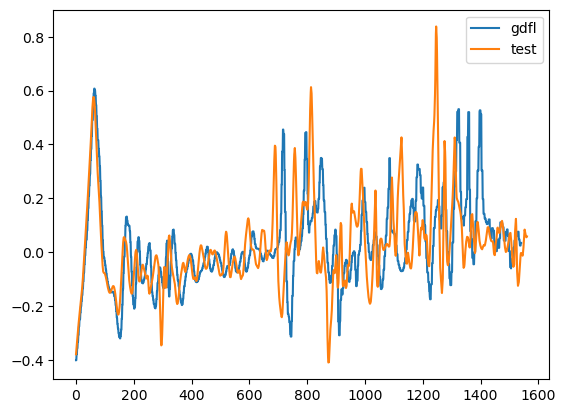

In [22]:
time_index = 20
gdfl_var = gfdl_uv[variable_name][time_index][0][:-150].values
test_var = test_uv[variable_name][time_index][0].values

plt.plot(gdfl_var, label = "gdfl")
plt.plot(test_var, label = "test")
plt.legend()

In [ ]:
gfdl_ic = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/gfdl_nwa12_data/glorys_ic_1993-01-01.nc")
regrid_ic = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/init_vel.nc")

hgrid = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/gfdl_copy.3.n3b/hgrid.nc")
gfdl_hgrid = xr.open_dataset("/glade/work/gmarques/Projects/NWA12/grid/ocean_hgrid.nc")
hgrid["lat"] = hgrid.y
hgrid["lon"] = hgrid.x
ugrid = (
            hgrid[["x", "y"]]
            .isel(nxp=slice(None, None, 2), nyp=slice(1, None, 2))
            .rename({"x": "lon", "y": "lat"})
            .set_coords(["lat", "lon"])
        )
vgrid = (
            hgrid[["x", "y"]]
            .isel(nxp=slice(1, None, 2), nyp=slice(None, None, 2))
            .rename({"x": "lon", "y": "lat"})
            .set_coords(["lat", "lon"])
        )

        ## Construct the cell centre grid for tracers (xh, yh).
tgrid = (
            hgrid[["x", "y"]]
            .isel(nxp=slice(1, None, 2), nyp=slice(1, None, 2))
            .rename({"x": "lon", "y": "lat", "nxp": "nx", "nyp": "ny"})
            .set_coords(["lat", "lon"])
        )


gfdl_ugrid = (
            gfdl_hgrid[["x", "y"]]
            .isel(nxp=slice(None, None, 2), nyp=slice(1, None, 2))
            .rename({"x": "lon", "y": "lat"})
            .set_coords(["lat", "lon"])
        )
gfdl_vgrid = (
            gfdl_hgrid[["x", "y"]]
            .isel(nxp=slice(1, None, 2), nyp=slice(None, None, 2))
            .rename({"x": "lon", "y": "lat"})
            .set_coords(["lat", "lon"])
        )

        ## Construct the cell centre grid for tracers (xh, yh).
gfdl_tgrid = (
            gfdl_hgrid[["x", "y"]]
            .isel(nxp=slice(1, None, 2), nyp=slice(1, None, 2))
            .rename({"x": "lon", "y": "lat", "nxp": "nx", "nyp": "ny"})
            .set_coords(["lat", "lon"])
        )

In [23]:
gfdl_hgrid.x.shape


(1691, 1551)

In [4]:
# Regrid Tracers
gfdl_ic["lat"] = (("yh","xh"),gfdl_tgrid.lat.values)
gfdl_ic["lon"] = (("yh","xh"),gfdl_tgrid.lon.values)
hgrid["lat"] = hgrid.y
hgrid["lon"] = hgrid.x
regrid_t = rm6.regridding.create_regridder(gfdl_ic, tgrid,locstream_out= False, method = "nearest_s2d")
temp_regridding = regrid_t(gfdl_ic.temp)
salt_regridding = regrid_t(gfdl_ic.salt)
eta_regridding = regrid_t(gfdl_ic.ssh)
# Regrid U
gfdl_ic["lon"] = (("yh","xq"),gfdl_ugrid.lon.values)
gfdl_ic["lat"] = (("yh","xq"),gfdl_ugrid.lat.values)
regrid_u = rm6.regridding.create_regridder(gfdl_ic, ugrid,locstream_out= False, method = "nearest_s2d")
u_regridding = regrid_u(gfdl_ic.u)

# Regrid V
gfdl_ic["lon"] = (("yq","xh"),gfdl_vgrid.lon.values)
gfdl_ic["lat"] = (("yq","xh"),gfdl_vgrid.lat.values)
regrid_v = rm6.regridding.create_regridder(gfdl_ic, vgrid,locstream_out= False, method = "nearest_s2d")
v_regridding = regrid_v(gfdl_ic.v)


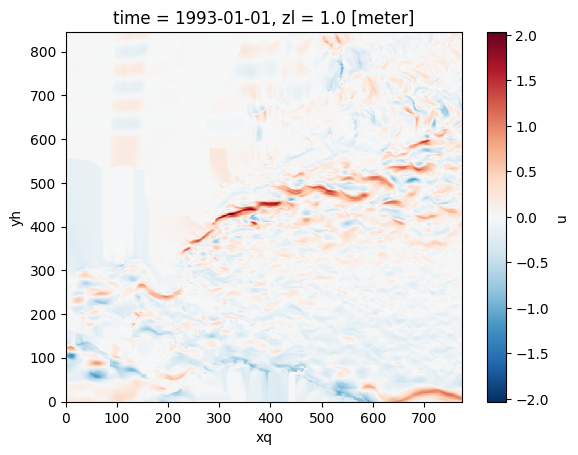

In [24]:
gfdl_ic.u[0][0].plot()

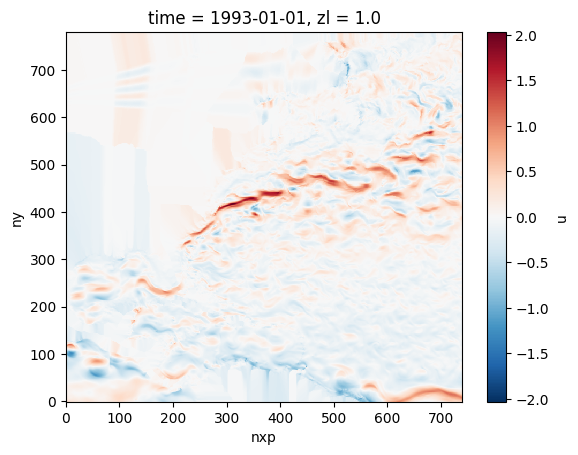

In [14]:
regrid_ic.u[0][0].plot()
gfdl_3 = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/gfdl_copy.3.n3b/init_vel.nc")

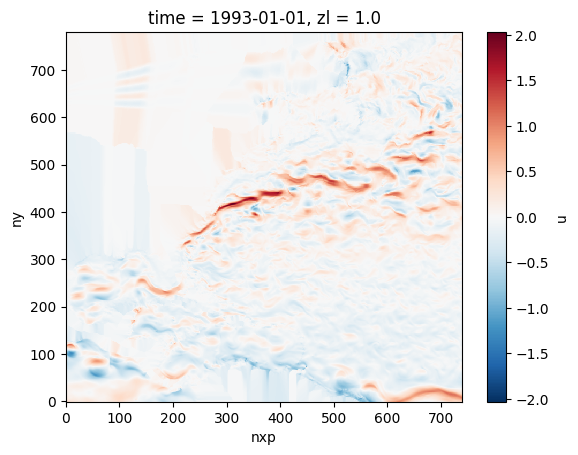

In [13]:
gfdl_3.u[0][0].plot()



In [5]:
tracers_out = (
    xr.merge(
        [
            temp_regridding.rename("temp"), salt_regridding.rename("salt")
        ]
    )
    .rename({"lon": "xh", "lat": "yh"})
    .transpose("time","zl", "ny", "nx")
)
tracers_out = tracers_out.assign_coords(
    {
        "nx": np.arange(tracers_out.sizes["nx"]).astype(float),
        "ny": np.arange(tracers_out.sizes["ny"]).astype(float),
    }
)
eta_out = (
            eta_regridding
            .rename({"lon": "xh", "lat": "yh"})
            .rename("eta_t")
            .transpose("time","ny", "nx")
        ) 
vel_out = xr.merge(
    [
        u_regridding
        .rename({"lon": "xq", "lat": "yh", "nyp": "ny"})
        .rename("u"),
        v_regridding
        .rename({"lon": "xh", "lat": "yq", "nxp": "nx"})
        .rename("v"),
    ]
)

In [7]:

import netCDF4
vel_out.fillna(0).to_netcdf(
    "/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/init_vel.nc",
    mode="w",
    encoding={
        "u": {"_FillValue": netCDF4.default_fillvals["f4"]},
        "v": {"_FillValue": netCDF4.default_fillvals["f4"]},
    },
)

tracers_out.to_netcdf(
    "/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/init_tracers.nc",
    mode="w",
    encoding={
        # "xh": {"_FillValue": None},
        # "yh": {"_FillValue": None},
        # "zl": {"_FillValue": None},
        "temp": {"_FillValue": -1e20, "missing_value": -1e20},
        "salt": {"_FillValue": -1e20, "missing_value": -1e20},
    },
)

eta_out.to_netcdf(
    "/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/init_eta.nc",
    mode="w",
    encoding={
        "eta_t": {"_FillValue": None},
    },
)
